# Подбор аналитической зависимости

Воспроизводимый эксперимент на синтетических данных. Установите пакет из корня проекта командой `uv sync --extra dev --extra notebook` и откройте ноутбук через `uv run jupyter lab`.

Сравним пять семейств (семь кандидатов с учётом степеней полинома) на одном временном разбиении. Коэффициенты подбираются только по обучающим строкам.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Math, display

from parametric_regression import (
    ExponentialFamily,
    ModelSelector,
    PolynomialFamily,
    RationalSaturationFamily,
    fit_family,
)
from parametric_regression.visualization import plot_fit

rng = np.random.default_rng(42)
x = np.linspace(0, 20, 120)
y_true = 2 + 5 * np.exp(-0.3 * x)
y = y_true + rng.normal(0, 0.03, x.size)
df = pd.DataFrame({"time": x, "response": y})
df.head()

,time,response
0,0.000000,7.009142
1,0.168067,6.722950
2,0.336134,6.542900
3,0.504202,6.326336
4,0.672269,6.028248


## Обучение и сравнение

Временное разбиение оставляет последние 20% уникальных значений аргумента для проверки. Выбор идёт по проверочному RMSE; при разнице в пределах 1% предпочитается меньшее число коэффициентов.

In [3]:
selector = ModelSelector(random_state=42, relative_tolerance=0.01)
result = selector.fit_dataframe(df, x_column="time", y_column="response", split="time")
assert result.success
print("Выбрано:", result.best_family)
print("Критерий:", result.criterion)
print("Разбиение:", result.split_protocol.method)
print("Коэффициенты:", result.coefficients)
print("Проверочные метрики:", result.metrics)
display(Math(result.latex_formula))
display(result.to_dataframe())

Выбрано: exponential
Критерий: validation_rmse
Разбиение: time
Коэффициенты: {'c': 1.9925198141028113, 'a': 4.994477260888605, 'b': -0.2975903746698557}
Проверочные метрики: {'mae': 0.02001179495204002, 'rmse': 0.024889227381760224, 'r2': -0.03956617529662809}


<IPython.core.display.Math object>

,family,success,selected,n_parameters,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,message,warnings
0,polynomial_1,True,False,2,0.519839,0.634405,0.750233,1.347638,1.375034,-3171.900569,Linear least squares converged.,
1,polynomial_2,True,False,3,0.192476,0.232768,0.966376,1.127353,1.211569,-2462.346299,Linear least squares converged.,
2,polynomial_3,True,False,4,0.056185,0.068312,0.997104,0.759935,0.878340,-1293.657344,Linear least squares converged.,
3,exponential,True,True,3,0.018732,0.022558,0.999684,0.020012,0.024889,-0.039566,`ftol` termination condition is satisfied.,
4,logistic,False,False,4,NaN,NaN,NaN,NaN,NaN,NaN,RuntimeError: No converged start. start 1: The...,
5,gompertz,True,False,4,0.018736,0.022561,0.999684,0.020016,0.024887,-0.039418,`xtol` termination condition is satisfied.,start 1: The maximum number of function evalua...
6,rational_saturation,True,False,3,0.082784,0.096226,0.994254,0.237640,0.242995,-98.089002,`ftol` termination condition is satisfied.,


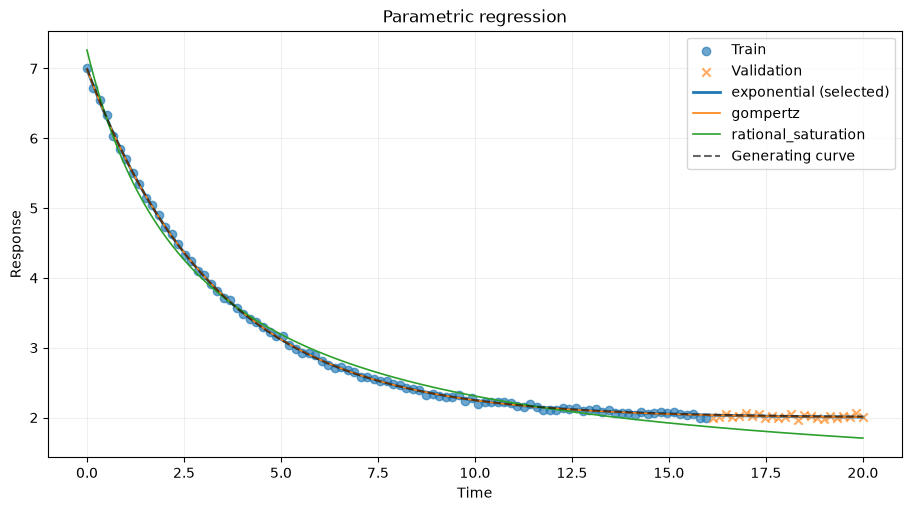

In [4]:
figure = plot_fit(result, x, y, top_n=3, xlabel="Time", ylabel="Response")
figure.axes[0].plot(x, y_true, "k--", label="Generating curve", alpha=0.6)
figure.axes[0].legend()
plt.show()
plt.close(figure)

## Прогнозы и явное переобучение

Результат селектора использует исходные обучающие коэффициенты. При необходимости после выбора можно отдельно оценить параметры по всем данным. Метрики этого нового результата будут обучающими, а не независимой проверкой.

In [5]:
new_x = np.array([21.0, 22.0, 23.0])
final_fit = fit_family(result.best_result.family, x, y)
assert final_fit.success
comparison = pd.DataFrame(
    {
        "x": new_x,
        "training_fit_prediction": result.predict(new_x),
        "full_data_fit_prediction": final_fit.predict(new_x),
        "generating_curve": 2 + 5 * np.exp(-0.3 * new_x),
    }
)
display(comparison)

,x,training_fit_prediction,full_data_fit_prediction,generating_curve
0,21.0,2.002167,2.002332,2.009182
1,22.0,1.999684,1.999851,2.006802
2,23.0,1.997840,1.998009,2.005039


## Несколько независимых экспериментов

Для проверки обобщения на новый эксперимент его строки должны целиком попадать в одну часть. Ниже синтетические повторы одной зависимости с небольшими сдвигами уровня. `experiment_id` используется только для разбиения.

Обучающие эксперименты: [2, 3, 4, 5]
Проверочные эксперименты: [0, 1]


,family,success,selected,n_parameters,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,message,warnings
0,polynomial_2,True,False,3,0.265882,0.324320,0.933734,0.256685,0.315697,0.937656,Linear least squares converged.,
1,exponential,True,True,3,0.054726,0.067151,0.997159,0.021620,0.027932,0.999512,`ftol` termination condition is satisfied.,
2,rational_saturation,True,False,3,0.120035,0.143106,0.987098,0.113179,0.129195,0.989559,`ftol` termination condition is satisfied.,


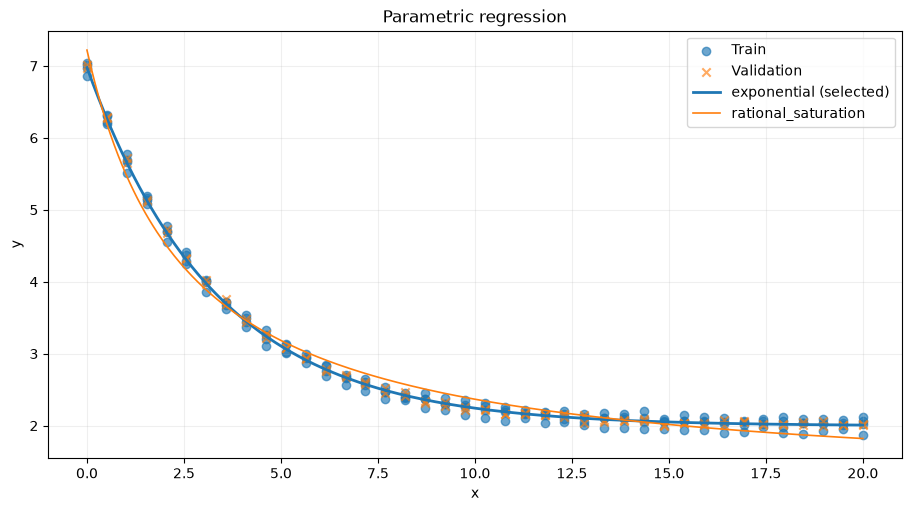

In [6]:
group_rng = np.random.default_rng(7)
frames = []
for experiment_id in range(6):
    t = np.linspace(0, 20, 40)
    offset = group_rng.normal(0, 0.05)
    response = 2 + offset + 5 * np.exp(-0.3 * t) + group_rng.normal(0, 0.03, t.size)
    frames.append(pd.DataFrame({"time": t, "response": response, "experiment_id": experiment_id}))
grouped = pd.concat(frames, ignore_index=True)
group_selector = ModelSelector(
    [PolynomialFamily(2), ExponentialFamily(), RationalSaturationFamily()],
    random_state=42,
)
group_result = group_selector.fit_dataframe(
    grouped,
    x_column="time",
    y_column="response",
    group_column="experiment_id",
    split="group",
)
train_groups = set(grouped.iloc[group_result.split_protocol.train_indices]["experiment_id"])
validation_groups = set(
    grouped.iloc[group_result.split_protocol.validation_indices]["experiment_id"]
)
assert train_groups.isdisjoint(validation_groups)
assert group_result.success
print("Обучающие эксперименты:", sorted(train_groups))
print("Проверочные эксперименты:", sorted(validation_groups))
display(group_result.to_dataframe())
figure = plot_fit(group_result, grouped["time"], grouped["response"], top_n=2)
plt.show()
plt.close(figure)

## Интерпретация

В этом эксперименте известна порождающая формула, поэтому можно проверить восстановление кривой. На реальных данных малая ошибка не доказывает уникальность коэффициентов или биологический механизм. Один holdout используется для выбора семейства; для независимой итоговой оценки нужен отдельный тестовый набор. Экстраполяция за диапазон наблюдений требует отдельной проверки.